Cell 1: Libraries import karo

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


Cell 2: Dataset load karo

In [3]:
DATA_PATH = Path("../data/Telco_customer_churn.xlsx")

df = pd.read_excel(
    DATA_PATH,
    sheet_name="Telco_Churn"
)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 7043
Columns: 33


Cell 3: Dataset ko samjho

In [4]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

Dataset shape: (7043, 33)

Column names:
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5 

Cell 4: Churn target ko samjho

Churn Label distribution:
Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn Label
No     73.46
Yes    26.54
Name: proportion, dtype: float64


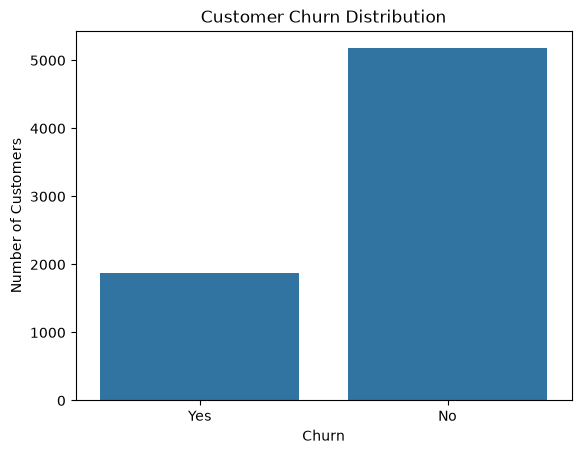

In [6]:
print("Churn Label distribution:")
print(df["Churn Label"].value_counts())

print("\nChurn percentage:")
print(
    (df["Churn Label"].value_counts(normalize=True) * 100)
    .round(2)
)

sns.countplot(data=df, x="Churn Label")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

Step 3 — Data cleaning abhi mat skip karna

In [7]:
print("Missing values per column:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nBlank strings in Total Charges:")
print(
    (df["Total Charges"].astype(str).str.strip() == "").sum()
)

print("\nDuplicate customer IDs:")
print(df["CustomerID"].duplicated().sum())

Missing values per column:
Churn Reason      5174
CustomerID           0
Count                0
State                0
Country              0
Zip Code             0
Lat Long             0
Latitude             0
City                 0
Gender               0
Senior Citizen       0
Partner              0
Dependents           0
Tenure Months        0
Phone Service        0
dtype: int64

Blank strings in Total Charges:
11

Duplicate customer IDs:
0


Step 5: Data Cleaning

In [8]:

# Step 5A: Total Charges ke blank records inspect karo

blank_mask = df["Total Charges"].astype(str).str.strip().eq("")

print("Blank Total Charges records:", blank_mask.sum())

display(
    df.loc[
        blank_mask,
        ["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges", "Churn Label"]
    ]
)


Blank Total Charges records: 11


,CustomerID,Tenure Months,Monthly Charges,Total Charges,Churn Label
2234,4472-LVYGI,0,52.55,,No
2438,3115-CZMZD,0,20.25,,No
2568,5709-LVOEQ,0,80.85,,No
2667,4367-NUYAO,0,25.75,,No
2856,1371-DWPAZ,0,56.05,,No
4331,7644-OMVMY,0,19.85,,No
4687,3213-VVOLG,0,25.35,,No
5104,2520-SGTTA,0,20.00,,No
5719,2923-ARZLG,0,19.70,,No
6772,4075-WKNIU,0,73.35,,No


In [9]:

# Step 5B: Clean dataset ki copy banao

df_clean = df.copy()

# Total Charges ko numeric format mein convert karo
df_clean["Total Charges"] = pd.to_numeric(
    df_clean["Total Charges"].astype(str).str.strip(),
    errors="coerce"
)

# Sirf un records mein 0 fill karo jahan tenure zero hai
zero_tenure_mask = df_clean["Tenure Months"].eq(0)

df_clean.loc[
    zero_tenure_mask & df_clean["Total Charges"].isna(),
    "Total Charges"
] = 0

print("Original dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)

print("\nTotal Charges missing values:")
print(df_clean["Total Charges"].isna().sum())

print("\nTotal Charges data type:")
print(df_clean["Total Charges"].dtype)

print("\nRemaining missing values:")
print(df_clean.isnull().sum().sort_values(ascending=False).head(10))


Original dataset shape: (7043, 33)
Clean dataset shape: (7043, 33)

Total Charges missing values:
0

Total Charges data type:
float64

Remaining missing values:
Churn Reason    5174
CustomerID         0
Count              0
State              0
Country            0
Zip Code           0
Lat Long           0
Latitude           0
City               0
Gender             0
dtype: int64


In [10]:

# Step 5C: Cleaned dataset validation

print("Dataset shape:", df_clean.shape)

print("\nTotal Charges data type:")
print(df_clean["Total Charges"].dtype)

print("\nTotal Charges missing values:")
print(df_clean["Total Charges"].isna().sum())

print("\nNegative Total Charges:")
print((df_clean["Total Charges"] < 0).sum())

print("\nChurn Label values:")
print(df_clean["Churn Label"].value_counts())

print("\nDuplicate Customer IDs:")
print(df_clean["CustomerID"].duplicated().sum())

print("\nNumerical columns summary:")
display(
    df_clean[
        ["Tenure Months", "Monthly Charges", "Total Charges"]
    ].describe().round(2)
)


Dataset shape: (7043, 33)

Total Charges data type:
float64

Total Charges missing values:
0

Negative Total Charges:
0

Churn Label values:
Churn Label
No     5174
Yes    1869
Name: count, dtype: int64

Duplicate Customer IDs:
0

Numerical columns summary:


,Tenure Months,Monthly Charges,Total Charges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


Step 6 — Exploratory Data Analysis (EDA)

Contract-wise churn percentage:


Churn Label,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


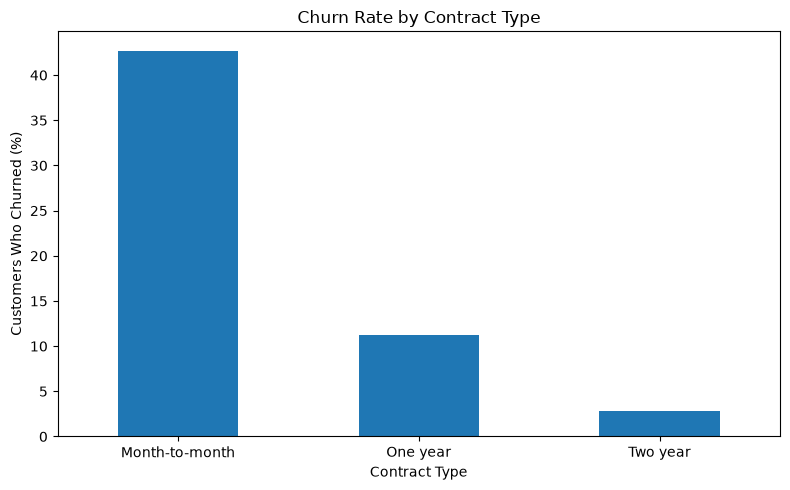

In [11]:

# Step 6A: Contract-wise churn rate

contract_churn = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn Label"],
    normalize="index"
) * 100

contract_churn = contract_churn.round(2)

print("Contract-wise churn percentage:")
display(contract_churn)

contract_churn["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Customers Who Churned (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


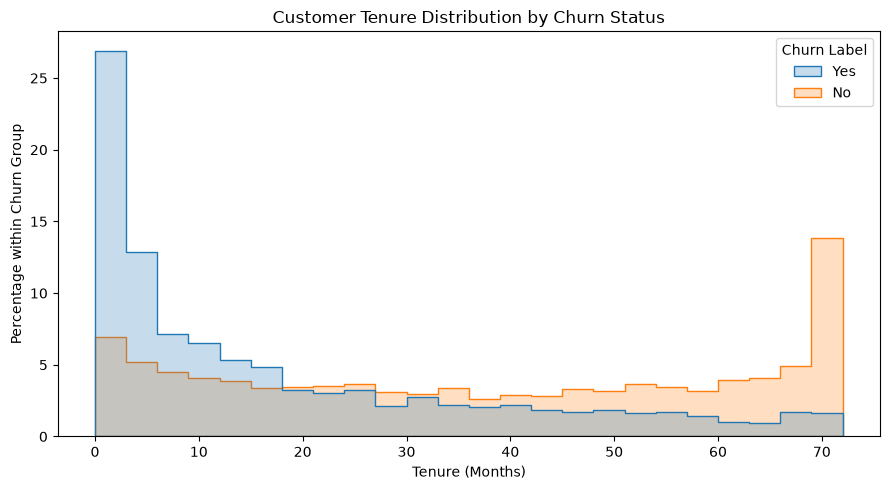

Average tenure by churn status:


Churn Label
No     37.57
Yes    17.98
Name: Tenure Months, dtype: float64

In [12]:
# Step 6B: Tenure distribution by churn status

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x="Tenure Months",
    hue="Churn Label",
    bins=24,
    kde=False,
    element="step",
    stat="percent",
    common_norm=False
)

plt.title("Customer Tenure Distribution by Churn Status")
plt.xlabel("Tenure (Months)")
plt.ylabel("Percentage within Churn Group")
plt.tight_layout()
plt.show()

print("Average tenure by churn status:")

display(
    df_clean.groupby("Churn Label")["Tenure Months"]
    .mean()
    .round(2)
)

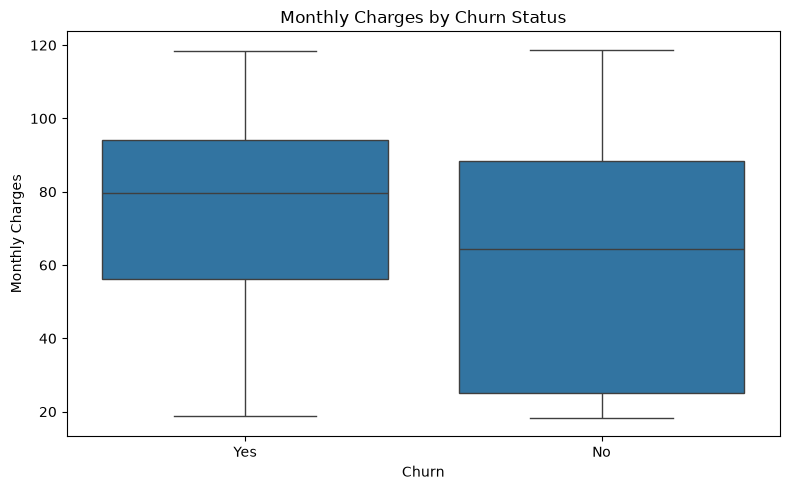


Monthly charges summary by churn:


,mean,median,min,max
Churn Label,,,,
No,61.27,64.43,18.25,118.75
Yes,74.44,79.65,18.85,118.35


In [13]:

# Step 6C: Monthly charges comparison

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x="Churn Label",
    y="Monthly Charges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

print("\nMonthly charges summary by churn:")
display(
    df_clean.groupby("Churn Label")["Monthly Charges"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
)


Churn Label,No,Yes
Payment Method,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


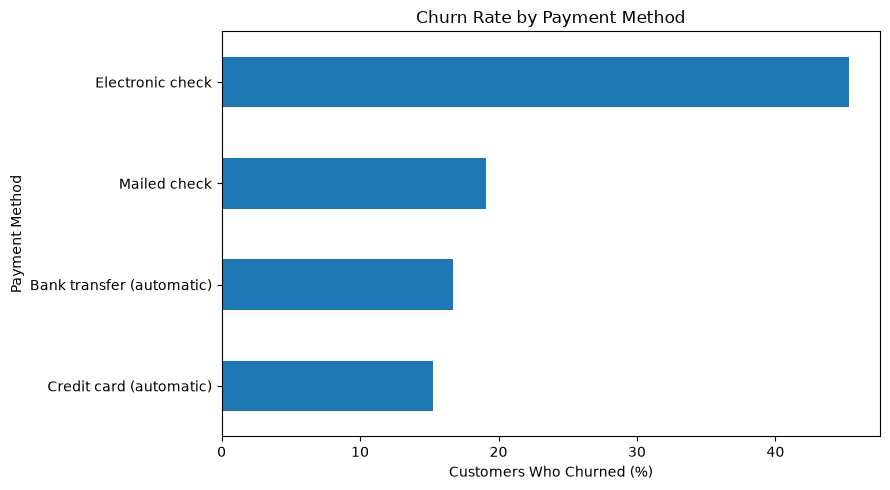

In [14]:

# Step 6D: Payment-method-wise churn rate

payment_churn = pd.crosstab(
    df_clean["Payment Method"],
    df_clean["Churn Label"],
    normalize="index"
) * 100

payment_churn = payment_churn.round(2)

display(payment_churn)

payment_churn["Yes"].sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Customers Who Churned (%)")
plt.ylabel("Payment Method")
plt.tight_layout()
plt.show()



Churn Analysis: Internet Service


Churn Label,No,Yes
Internet Service,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


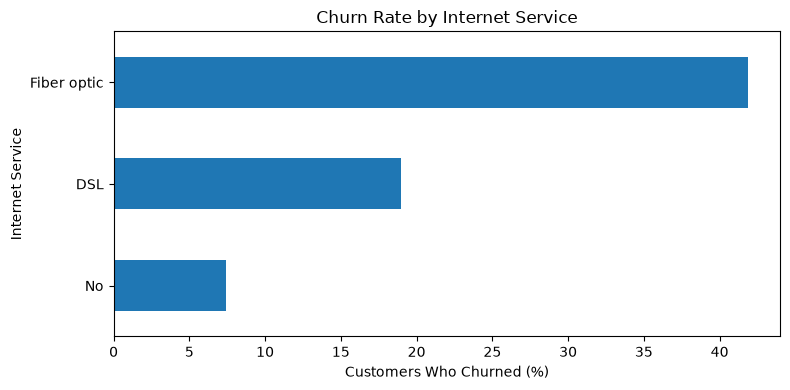


Churn Analysis: Tech Support


Churn Label,No,Yes
Tech Support,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


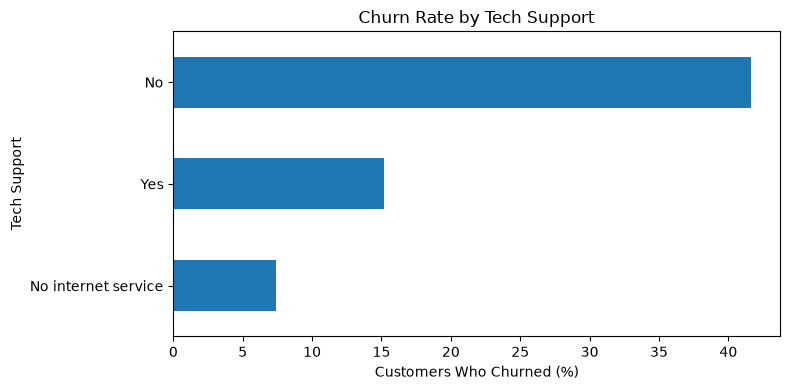


Churn Analysis: Online Security


Churn Label,No,Yes
Online Security,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


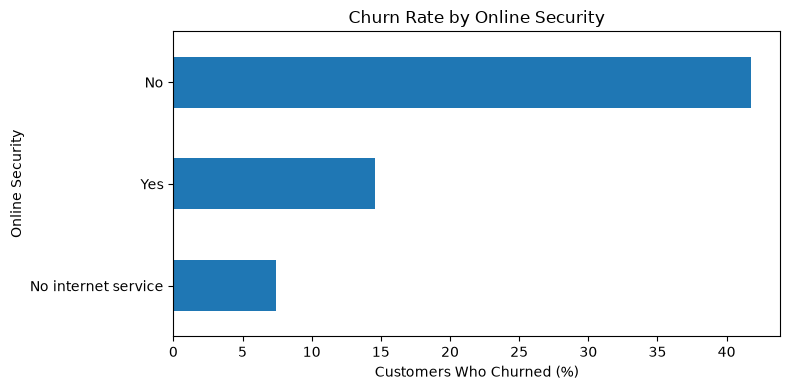


Churn Analysis: Online Backup


Churn Label,No,Yes
Online Backup,,
No,60.07,39.93
No internet service,92.60,7.40
Yes,78.47,21.53


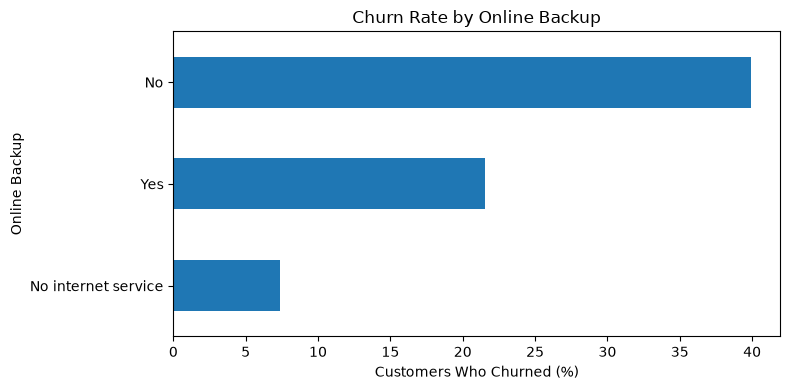


Churn Analysis: Device Protection


Churn Label,No,Yes
Device Protection,,
No,60.87,39.13
No internet service,92.60,7.40
Yes,77.50,22.50


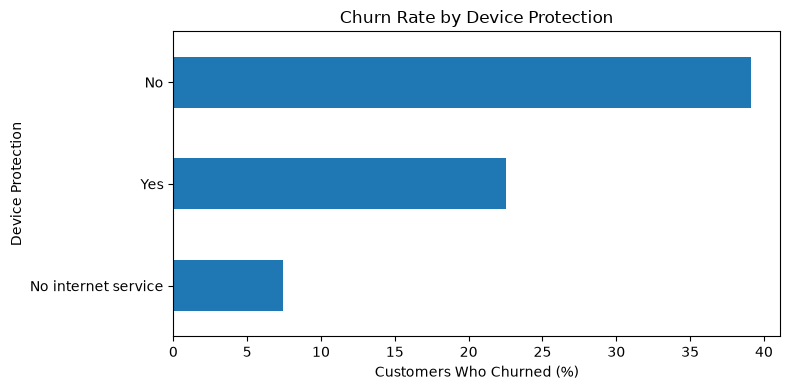


Churn Analysis: Senior Citizen


Churn Label,No,Yes
Senior Citizen,,
No,76.39,23.61
Yes,58.32,41.68


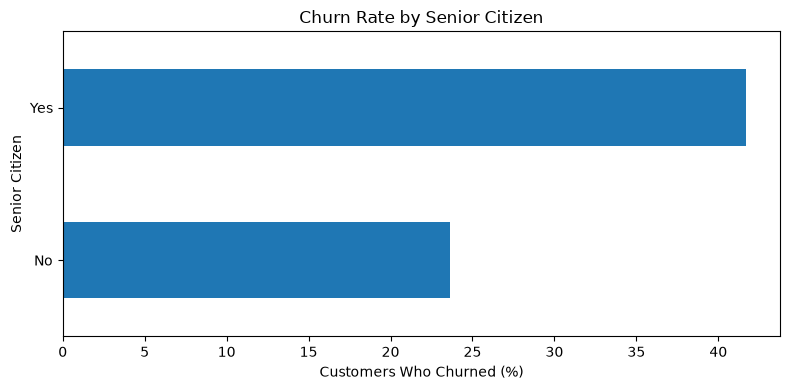


Churn Analysis: Paperless Billing


Churn Label,No,Yes
Paperless Billing,,
No,83.67,16.33
Yes,66.43,33.57


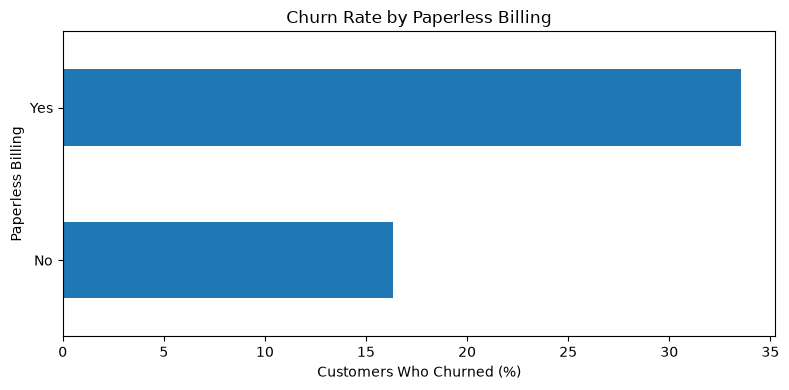


Churn Analysis: Dependents


Churn Label,No,Yes
Dependents,,
No,67.45,32.55
Yes,93.48,6.52


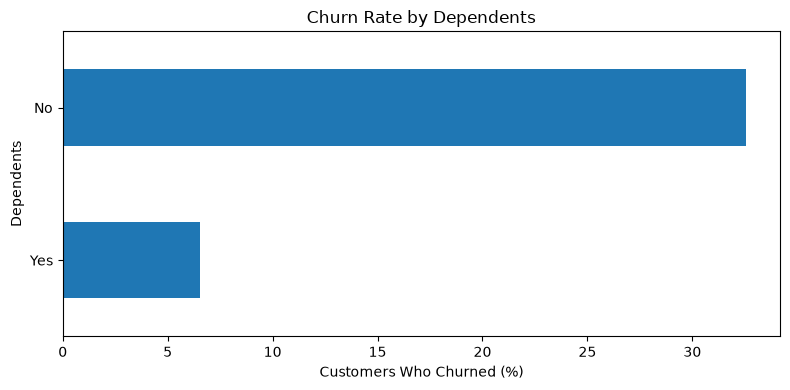


Churn Analysis: Partner


Churn Label,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


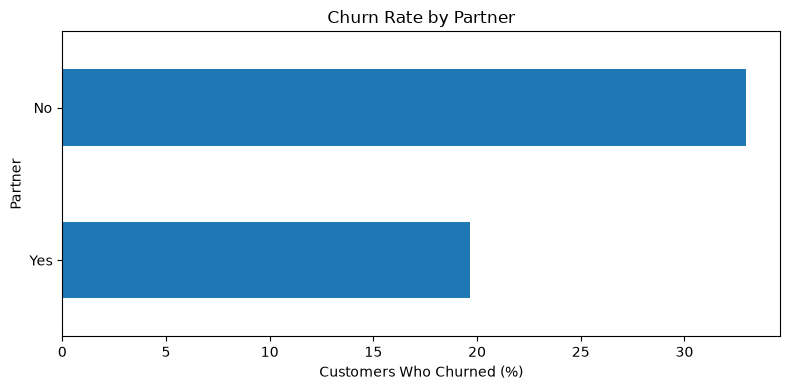

In [15]:

# Step 6E: Categorical features ka churn analysis

features = [
    "Internet Service",
    "Tech Support",
    "Online Security",
    "Online Backup",
    "Device Protection",
    "Senior Citizen",
    "Paperless Billing",
    "Dependents",
    "Partner"
]

for feature in features:
    print(f"\n{'=' * 55}")
    print(f"Churn Analysis: {feature}")
    print(f"{'=' * 55}")

    churn_table = pd.crosstab(
        df_clean[feature],
        df_clean["Churn Label"],
        normalize="index"
    ) * 100

    churn_table = churn_table.round(2)

    display(churn_table)

    if "Yes" in churn_table.columns:
        churn_table["Yes"].sort_values().plot(
            kind="barh",
            figsize=(8, 4)
        )

        plt.title(f"Churn Rate by {feature}")
        plt.xlabel("Customers Who Churned (%)")
        plt.ylabel(feature)
        plt.tight_layout()
        plt.show()


In [16]:

# Step 6F: Numerical features comparison

numerical_features = [
    "Tenure Months",
    "Monthly Charges",
    "Total Charges",
    "CLTV"
]

comparison = df_clean.groupby("Churn Label")[
    numerical_features
].agg(["mean", "median"])

display(comparison.round(2))


Tenure Months        Monthly Charges        Total Charges  \
                     mean median            mean median          mean   
Churn Label                                                             
No                  37.57   38.0           61.27  64.43       2549.91   
Yes                 17.98   10.0           74.44  79.65       1531.80   

                         CLTV          
              median     mean  median  
Churn Label                            
No           1679.52  4490.92  4620.0  
Yes           703.55  4149.41  4238.0


Churn analysis: Gender


Churn Label,No,Yes
Gender,,
Female,73.08,26.92
Male,73.84,26.16


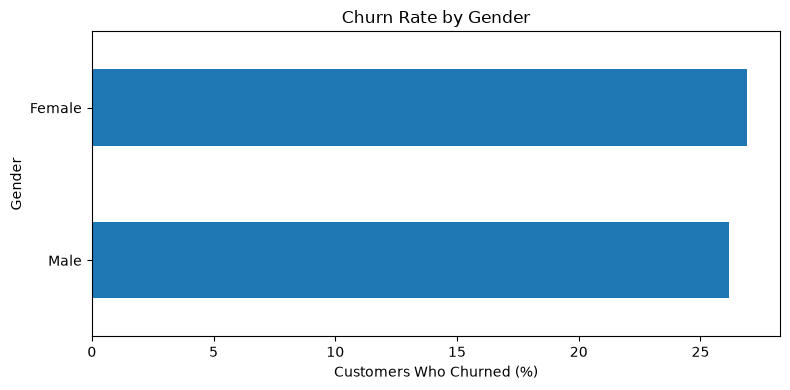


Churn analysis: Phone Service


Churn Label,No,Yes
Phone Service,,
No,75.07,24.93
Yes,73.29,26.71


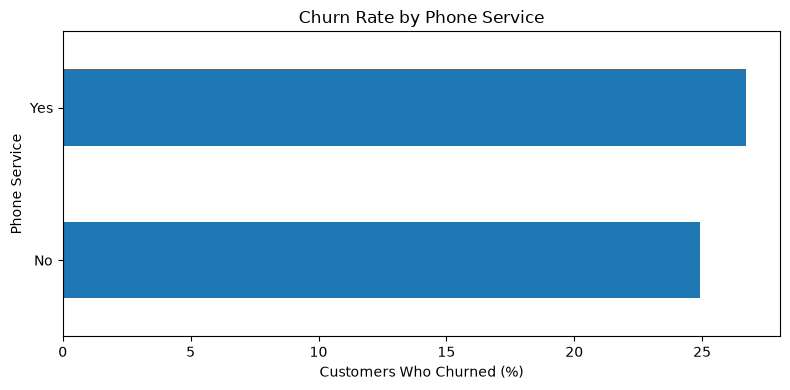


Churn analysis: Multiple Lines


Churn Label,No,Yes
Multiple Lines,,
No,74.96,25.04
No phone service,75.07,24.93
Yes,71.39,28.61


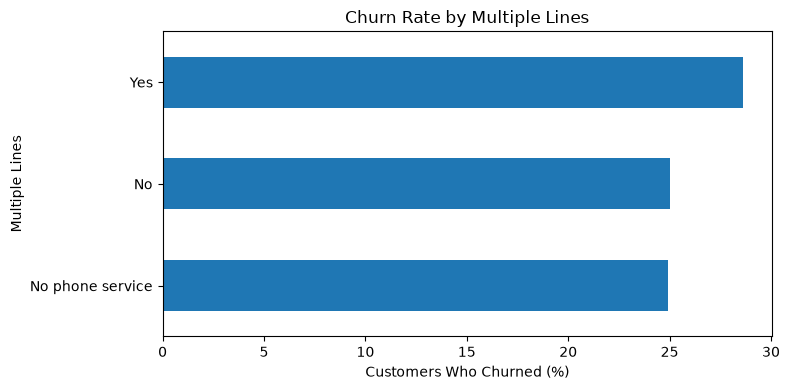


Churn analysis: Streaming TV


Churn Label,No,Yes
Streaming TV,,
No,66.48,33.52
No internet service,92.60,7.40
Yes,69.93,30.07


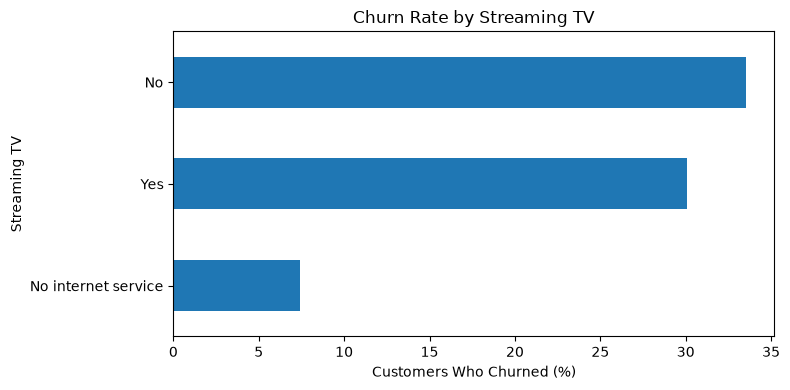


Churn analysis: Streaming Movies


Churn Label,No,Yes
Streaming Movies,,
No,66.32,33.68
No internet service,92.60,7.40
Yes,70.06,29.94


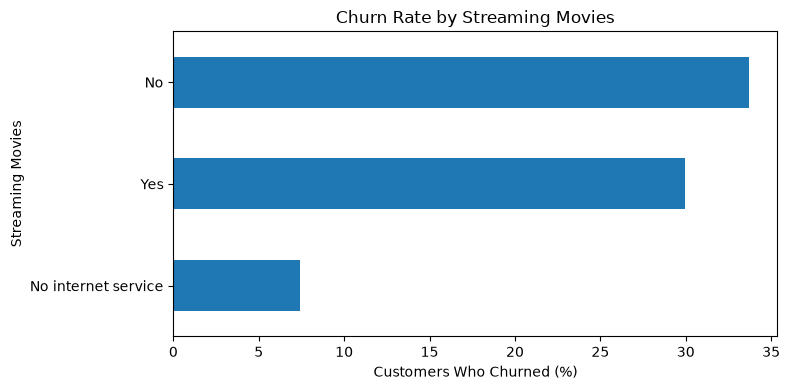

In [17]:

# Step 6G: Additional categorical feature analysis

features_extra = [
    "Gender",
    "Phone Service",
    "Multiple Lines",
    "Streaming TV",
    "Streaming Movies"
]

for feature in features_extra:
    print(f"\nChurn analysis: {feature}")

    churn_table = pd.crosstab(
        df_clean[feature],
        df_clean["Churn Label"],
        normalize="index"
    ) * 100

    churn_table = churn_table.round(2)
    display(churn_table)

    churn_table["Yes"].sort_values().plot(
        kind="barh",
        figsize=(8, 4)
    )

    plt.title(f"Churn Rate by {feature}")
    plt.xlabel("Customers Who Churned (%)")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()


## Step 6H — Exploratory Data Analysis: Key Findings

### 1. Contract Type
Month-to-month customers have a churn rate of 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.

### 2. Customer Tenure
Customers who churned had an average tenure of 17.98 months, compared with 37.57 months for customers who did not churn. The median tenure was 10 months for churned customers and 38 months for non-churned customers.

### 3. Monthly Charges
Customers who churned had higher average monthly charges (74.44) than customers who did not churn (61.27).

### 4. Payment Method
Electronic check users had the highest observed churn rate at 45.29%, compared with 15.24% for automatic credit-card payments and 16.71% for automatic bank transfers.

### 5. Internet and Support Services
Fiber-optic customers had a churn rate of 41.89%. Customers without Tech Support and Online Security had churn rates of 41.64% and 41.77%, respectively.

### 6. Customer Characteristics
The observed churn rate was higher among senior citizens (41.68%) than non-senior citizens (23.61%). Customers with dependents had a lower churn rate (6.52%) than customers without dependents (32.55%).

### Conclusion
The exploratory analysis identifies several characteristics associated with customer churn, particularly contract type, tenure, payment method, monthly charges, internet service and support-service usage. These patterns can guide feature selection and further investigation. They do not establish causal relationships, and their predictive value must be evaluated using held-out test data.

Step 7: Machine learning pipeline

In [18]:

# Step 7A: Target aur feature columns define karna

target_column = "Churn Label"

# Initial model se exclude kiye jaane wale columns
columns_to_drop = [
    "CustomerID",       # Customer identifier
    "Count",            # Record-count field
    "Country",          # Location field
    "State",            # Location field
    "City",             # High-cardinality location field
    "Zip Code",         # Location identifier
    "Lat Long",         # Geographic coordinates as text
    "Latitude",         # Geographic location
    "Longitude",        # Geographic location
    "Churn Value",      # Churn Label ka duplicate representation
    "Churn Score",      # Potential leakage risk
    "Churn Reason",     # Outcome-related information
    "CLTV"              # Meaning/timing verify hone tak excluded
]

# Original cleaned data ko preserve karna
model_data = df_clean.copy()

# Target ko binary format mein convert karna
y = model_data[target_column].map({
    "No": 0,
    "Yes": 1
})

# Features se target aur excluded columns hataana
X = model_data.drop(
    columns=[target_column] + columns_to_drop,
    errors="ignore"
)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nFeature columns:")
print(X.columns.tolist())

print("\nMissing target values:", y.isna().sum())
print("Missing values in features:", X.isna().sum().sum())


Feature matrix shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn Label
0    5174
1    1869
Name: count, dtype: int64

Feature columns:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges']

Missing target values: 0
Missing values in features: 0


In [19]:

# Step 7B: Feature selection verification

print("X and y have the same number of rows:", len(X) == len(y))

print("\nTarget contains only 0 and 1:")
print(sorted(y.dropna().unique()))

print("\nPotential leakage columns still in X:")
leakage_check = [
    "Churn Label",
    "Churn Value",
    "Churn Score",
    "Churn Reason",
    "CLTV",
    "CustomerID"
]

print([col for col in leakage_check if col in X.columns])

print("\nFeature data types:")
display(X.dtypes.value_counts())


X and y have the same number of rows: True

Target contains only 0 and 1:
[np.int64(0), np.int64(1)]

Potential leakage columns still in X:
[]

Feature data types:


str        16
float64     2
int64       1
Name: count, dtype: int64

Step 8 — Train-Test Split and Data Preprocessing

In [20]:
# Step 8A: Required libraries import karo

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Features ko categorical aur numerical columns mein divide karo
categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

print("\nCategorical columns:")
print(categorical_features)

print("\nNumerical columns:")
print(numerical_features)

# 80% training aur 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Categorical features: 16
Numerical features: 3

Categorical columns:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']

Numerical columns:
['Tenure Months', 'Monthly Charges', 'Total Charges']

Training data shape: (5634, 19)
Testing data shape: (1409, 19)

Training target distribution:
Churn Label
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn Label
0    0.735
1    0.265
Name: proportion, dtype: float64


In [21]:
# Step 8B: Categorical aur numerical preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


Step 9 — Logistic Regression Baseline Model

In [22]:
# Step 9A: Logistic Regression baseline model

from sklearn.linear_model import LogisticRegression

# Preprocessing + model ko ek single pipeline mein combine karo
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

# Sirf training data se model train hoga
baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression trained successfully!")
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Baseline Logistic Regression trained successfully!
Training rows: 5634
Testing rows: 1409


BASELINE MODEL PERFORMANCE
----------------------------------------
Accuracy                      : 0.8020
Precision                     : 0.6435
Recall                        : 0.5695
F1 Score                      : 0.6043
ROC-AUC                       : 0.8489
PR-AUC (Average Precision)    : 0.6453

Classification Report:
              precision    recall  f1-score   support

    No Churn      0.851     0.886     0.868      1035
       Churn      0.644     0.570     0.604       374

    accuracy                          0.802      1409
   macro avg      0.747     0.728     0.736      1409
weighted avg      0.796     0.802     0.798      1409



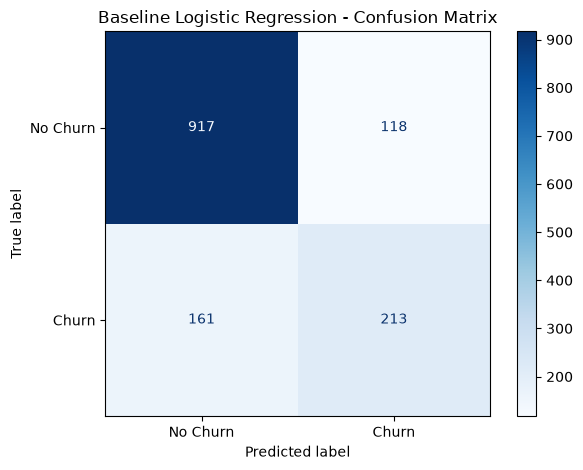

In [23]:
# Step 9B: Evaluate baseline model on unseen test data

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Predictions
y_pred = baseline_model.predict(X_test)
y_proba = baseline_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
baseline_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
    "PR-AUC (Average Precision)": average_precision_score(
        y_test, y_proba
    )
}

print("BASELINE MODEL PERFORMANCE")
print("-" * 40)

for metric, score in baseline_metrics.items():
    print(f"{metric:30s}: {score:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        digits=3,
        zero_division=0
    )
)

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    values_format="d"
)

plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

Step 10 — Model Comparison

In [24]:
# Step 10A: Compare multiple machine-learning algorithms

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Dummy Baseline": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]),

    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(
            max_depth=8,
            min_samples_leaf=10,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

# Har model ko sirf training data par train karo
for name, model in models.items():
    print(f"Training: {name} ...")
    model.fit(X_train, y_train)

print("\nAll models trained successfully!")

Training: Dummy Baseline ...
Training: Logistic Regression ...
Training: Decision Tree ...
Training: Random Forest ...

All models trained successfully!


In [25]:
# Step 10B: Evaluate all models on the same test set

comparison_results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(
            y_test, probabilities
        )
    })

comparison_df = (
    pd.DataFrame(comparison_results)
    .set_index("Model")
    .sort_values("F1 Score", ascending=False)
)

display(comparison_df.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
Model,,,,,,
Random Forest,0.7892,0.5937,0.6524,0.6217,0.8461,0.6481
Decision Tree,0.7395,0.5061,0.7781,0.6133,0.8248,0.6207
Logistic Regression,0.8020,0.6435,0.5695,0.6043,0.8489,0.6453
Dummy Baseline,0.7346,0.0000,0.0000,0.0000,0.5000,0.2654


Provisional top model: Random Forest


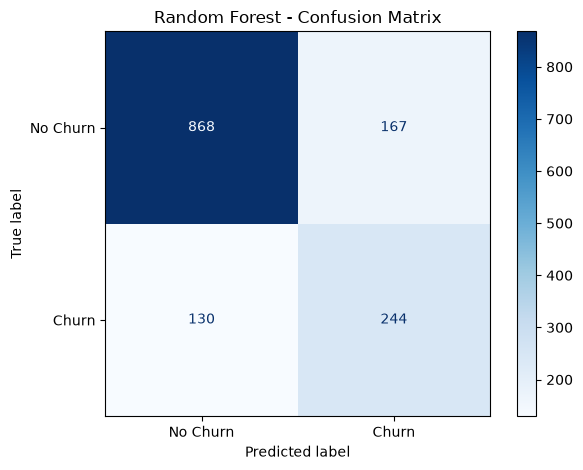


Classification Report:
              precision    recall  f1-score   support

    No Churn      0.870     0.839     0.854      1035
       Churn      0.594     0.652     0.622       374

    accuracy                          0.789      1409
   macro avg      0.732     0.746     0.738      1409
weighted avg      0.796     0.789     0.792      1409



In [26]:
# Step 10C: Inspect the provisional top model

best_model_name = comparison_df.index[0]
best_model = models[best_model_name]

print("Provisional top model:", best_model_name)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_model.predict(X_test),
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"{best_model_name} - Confusion Matrix")
plt.tight_layout()
plt.show()

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_model.predict(X_test),
        target_names=["No Churn", "Churn"],
        digits=3,
        zero_division=0
    )
)

Step 11 — Cross-Validation and Model Tuning

In [27]:
# Step 11A: Cross-validation on training data only

from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring_metrics = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

cv_results = []

# Test set ko CV mein use nahi karna
for name, model in models.items():
    print(f"Cross-validating: {name}")

    scores = cross_validate(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        scoring=scoring_metrics,
        n_jobs=1,
        return_train_score=False
    )

    row = {"Model": name}

    for metric in scoring_metrics:
        values = scores[f"test_{metric}"]
        row[f"{metric.upper()} Mean"] = values.mean()
        row[f"{metric.upper()} Std"] = values.std()

    cv_results.append(row)

cv_df = (
    pd.DataFrame(cv_results)
    .set_index("Model")
    .sort_values("F1 Mean", ascending=False)
)

display(cv_df.round(4))

Cross-validating: Dummy Baseline


C:\Users\vashi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\vashi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\vashi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\metrics\_classification.py:18

Cross-validating: Logistic Regression
Cross-validating: Decision Tree
Cross-validating: Random Forest


,ACCURACY Mean,ACCURACY Std,PRECISION Mean,PRECISION Std,RECALL Mean,RECALL Std,F1 Mean,F1 Std,ROC_AUC Mean,ROC_AUC Std,PR_AUC Mean,PR_AUC Std
Model,,,,,,,,,,,,
Random Forest,0.7952,0.0101,0.6046,0.0166,0.6582,0.0293,0.6302,0.0217,0.8532,0.0096,0.6572,0.0253
Logistic Regression,0.8119,0.0117,0.6667,0.0237,0.5819,0.0421,0.6208,0.0294,0.8590,0.0126,0.6800,0.0204
Decision Tree,0.7417,0.0134,0.5087,0.0163,0.7906,0.0294,0.6190,0.0191,0.8288,0.0071,0.6281,0.0147
Dummy Baseline,0.7346,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.2654,0.0001


Step 12 — Hyperparameter Tuning

In [28]:
# Step 12A: Tune Logistic Regression using training data only

from sklearn.model_selection import GridSearchCV

lr_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"]
}

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

lr_search.fit(X_train, y_train)

print("Best Logistic Regression parameters:")
print(lr_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(lr_search.best_score_, 4))

Best Logistic Regression parameters:
{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}

Best cross-validation F1-score:
0.6419


In [29]:
# Step 12B: Tune Random Forest using training data only

from sklearn.model_selection import RandomizedSearchCV

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

rf_param_distributions = {
    "classifier__n_estimators": [150, 250, 350],
    "classifier__max_depth": [None, 10, 15, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", 0.8],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=15,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

rf_search.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(rf_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(rf_search.best_score_, 4))

Best Random Forest parameters:
{'classifier__n_estimators': 250, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 10, 'classifier__class_weight': 'balanced'}

Best cross-validation F1-score:
0.649


In [30]:
# Step 12C: Compare tuned models using their CV results

tuned_models = {
    "Tuned Logistic Regression": lr_search.best_estimator_,
    "Tuned Random Forest": rf_search.best_estimator_
}

tuned_comparison = pd.DataFrame([
    {
        "Model": name,
        "Best CV F1": search.best_score_,
        "Best Parameters": str(search.best_params_)
    }
    for name, search in [
        ("Tuned Logistic Regression", lr_search),
        ("Tuned Random Forest", rf_search)
    ]
]).set_index("Model")

display(tuned_comparison.round(4))

,Best CV F1,Best Parameters
Model,,
Tuned Logistic Regression,0.6419,"{'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}"
Tuned Random Forest,0.6490,"{'classifier__n_estimators': 250, 'classifier__min_samples_split': 10, 'classifier__min_samples_..."


Step 13 — Tuned Model Evaluation

In [31]:
# Step 13A: Multi-metric cross-validation for tuned models

tuned_cv_results = []

for name, model in tuned_models.items():
    print(f"Evaluating: {name}")

    scores = cross_validate(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        scoring=scoring_metrics,
        n_jobs=1,
        return_train_score=False
    )

    row = {"Model": name}

    for metric in scoring_metrics:
        values = scores[f"test_{metric}"]
        row[f"{metric.upper()} Mean"] = values.mean()
        row[f"{metric.upper()} Std"] = values.std()

    tuned_cv_results.append(row)

tuned_cv_df = (
    pd.DataFrame(tuned_cv_results)
    .set_index("Model")
    .sort_values("F1 Mean", ascending=False)
)

display(tuned_cv_df.round(4))

Evaluating: Tuned Logistic Regression
Evaluating: Tuned Random Forest


,ACCURACY Mean,ACCURACY Std,PRECISION Mean,PRECISION Std,RECALL Mean,RECALL Std,F1 Mean,F1 Std,ROC_AUC Mean,ROC_AUC Std,PR_AUC Mean,PR_AUC Std
Model,,,,,,,,,,,,
Tuned Random Forest,0.7735,0.0121,0.5518,0.0178,0.7886,0.0236,0.6490,0.0144,0.8613,0.0076,0.6757,0.0171
Tuned Logistic Regression,0.7609,0.0141,0.5330,0.0184,0.8074,0.0294,0.6419,0.0189,0.8584,0.0122,0.6788,0.0204


Step 14 — Decision Threshold Tuning

In [32]:
# Step 14A: Find the best F1 threshold using out-of-fold predictions

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_grid = np.round(np.arange(0.05, 0.951, 0.01), 2)

threshold_results = {}
threshold_summaries = []

for name, model in tuned_models.items():
    print(f"Generating out-of-fold probabilities: {name}")

    # Each training row gets a probability from a model
    # that did not train on that row's fold.
    oof_probabilities = cross_val_predict(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=1
    )[:, 1]

    rows = []

    for threshold in threshold_grid:
        predictions = (
            oof_probabilities >= threshold
        ).astype(int)

        precision = precision_score(
            y_train, predictions, zero_division=0
        )
        recall = recall_score(
            y_train, predictions, zero_division=0
        )
        f1 = f1_score(
            y_train, predictions, zero_division=0
        )

        rows.append({
            "Threshold": threshold,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1
        })

    threshold_df = pd.DataFrame(rows)

    # If multiple thresholds tie, prefer the one closest to 0.50
    best_row = (
        threshold_df
        .assign(DistanceFrom050=lambda d: (d["Threshold"] - 0.50).abs())
        .sort_values(
            ["F1 Score", "DistanceFrom050"],
            ascending=[False, True]
        )
        .iloc[0]
    )

    threshold_results[name] = {
        "model": model,
        "threshold": float(best_row["Threshold"]),
        "oof_probabilities": oof_probabilities,
        "threshold_table": threshold_df
    }

    threshold_summaries.append({
        "Model": name,
        "Best Threshold": best_row["Threshold"],
        "OOF Precision": best_row["Precision"],
        "OOF Recall": best_row["Recall"],
        "OOF F1": best_row["F1 Score"]
    })

threshold_summary_df = (
    pd.DataFrame(threshold_summaries)
    .set_index("Model")
    .sort_values("OOF F1", ascending=False)
)

display(threshold_summary_df.round(4))

Generating out-of-fold probabilities: Tuned Logistic Regression
Generating out-of-fold probabilities: Tuned Random Forest


,Best Threshold,OOF Precision,OOF Recall,OOF F1
Model,,,,
Tuned Logistic Regression,0.56,0.5680,0.7659,0.6522
Tuned Random Forest,0.52,0.5623,0.7726,0.6509


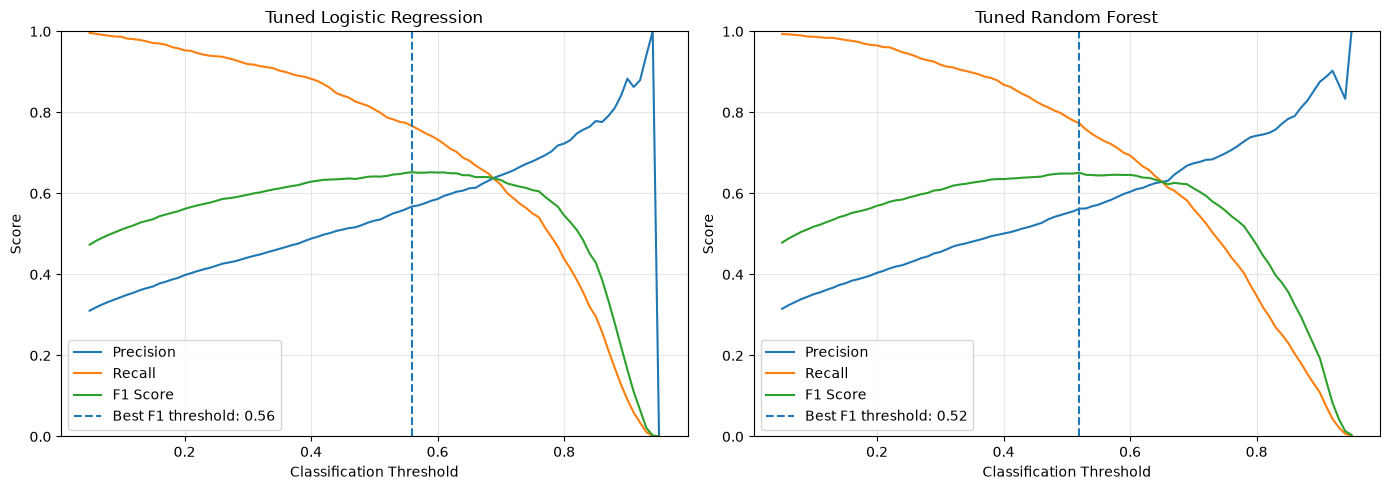

In [33]:
# Step 14B: Plot precision, recall and F1 across thresholds

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, result) in zip(axes, threshold_results.items()):
    table = result["threshold_table"]
    best_threshold = result["threshold"]

    ax.plot(
        table["Threshold"],
        table["Precision"],
        label="Precision"
    )
    ax.plot(
        table["Threshold"],
        table["Recall"],
        label="Recall"
    )
    ax.plot(
        table["Threshold"],
        table["F1 Score"],
        label="F1 Score"
    )

    ax.axvline(
        best_threshold,
        linestyle="--",
        label=f"Best F1 threshold: {best_threshold:.2f}"
    )

    ax.set_title(name)
    ax.set_xlabel("Classification Threshold")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

Step 15 — Feature Importance and Explainability

In [34]:
# Step 15A: Extract Logistic Regression feature coefficients

lr_final_candidate = lr_search.best_estimator_

fitted_preprocessor = lr_final_candidate.named_steps["preprocessor"]
fitted_classifier = lr_final_candidate.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_classifier.coef_[0]

lr_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds_Ratio": np.exp(coefficients),
    "Absolute_Importance": np.abs(coefficients)
})

lr_importance_df = lr_importance_df.sort_values(
    "Absolute_Importance",
    ascending=False
)

display(lr_importance_df.head(20).round(4))

,Feature,Coefficient,Odds_Ratio,Absolute_Importance
43,numerical__Tenure Months,-1.0207,0.3604,1.0207
6,categorical__Dependents_No,0.7679,2.1552,0.7679
7,categorical__Dependents_Yes,-0.7676,0.4641,0.7676
34,categorical__Contract_Month-to-month,0.6894,1.9926,0.6894
36,categorical__Contract_Two year,-0.6107,0.5430,0.6107
14,categorical__Internet Service_Fiber optic,0.3564,1.4282,0.3564
45,numerical__Total Charges,0.3079,1.3606,0.3079
41,categorical__Payment Method_Electronic check,0.2862,1.3313,0.2862
13,categorical__Internet Service_DSL,-0.2859,0.7514,0.2859
16,categorical__Online Security_No,0.2341,1.2637,0.2341


In [35]:
# Step 15B: Extract Random Forest feature importance

rf_final_candidate = rf_search.best_estimator_

rf_preprocessor = rf_final_candidate.named_steps["preprocessor"]
rf_classifier = rf_final_candidate.named_steps["classifier"]

rf_feature_names = rf_preprocessor.get_feature_names_out()
rf_importances = rf_classifier.feature_importances_

rf_importance_df = pd.DataFrame({
    "Feature": rf_feature_names,
    "Importance": rf_importances
}).sort_values("Importance", ascending=False)

display(rf_importance_df.head(20).round(4))

,Feature,Importance
34,categorical__Contract_Month-to-month,0.1218
43,numerical__Tenure Months,0.1177
45,numerical__Total Charges,0.0887
36,categorical__Contract_Two year,0.0641
44,numerical__Monthly Charges,0.0611
25,categorical__Tech Support_No,0.0498
16,categorical__Online Security_No,0.0487
7,categorical__Dependents_Yes,0.0471
6,categorical__Dependents_No,0.0460
14,categorical__Internet Service_Fiber optic,0.0440


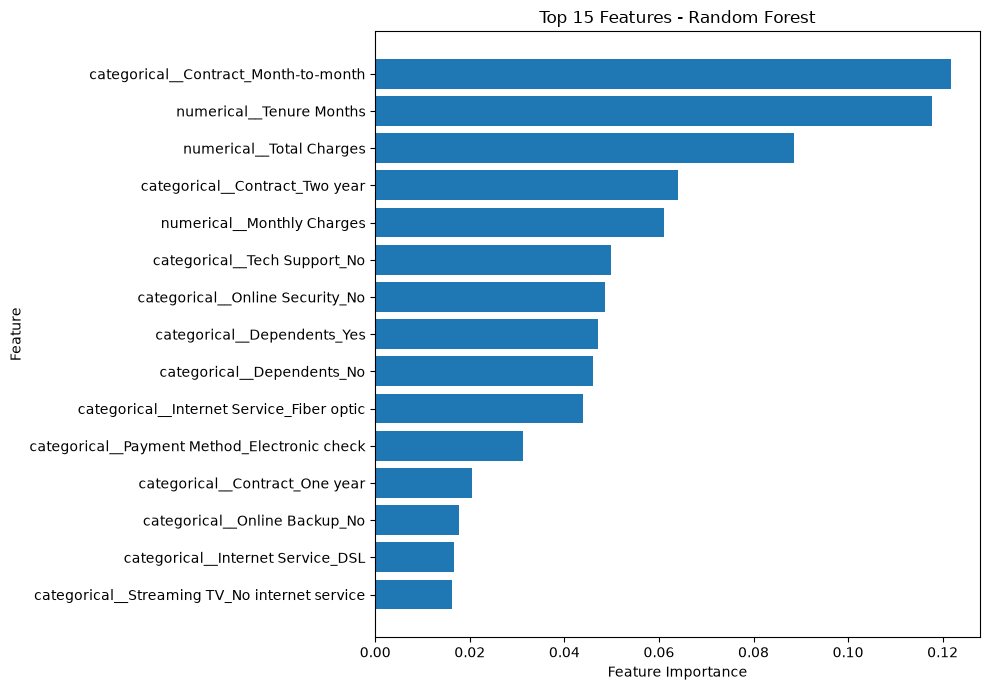

In [36]:
# Step 15C: Visualize top Random Forest features

top_features = rf_importance_df.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features - Random Forest")
plt.tight_layout()
plt.show()

Step 16 — Final Test Evaluation

In [37]:

# Step 16A: Final Test Evaluation at Default and Tuned Thresholds

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)
import pandas as pd

# Thresholds selected using training-data out-of-fold predictions
selected_thresholds = {
    "Tuned Logistic Regression": 0.56,
    "Tuned Random Forest": 0.52
}

final_test_results = []
final_test_predictions = {}

for model_name, model in tuned_models.items():

    # Actual churn labels and predicted probabilities
    y_probability = model.predict_proba(X_test)[:, 1]

    # Compare default threshold and CV-selected threshold
    thresholds_to_test = {
        "Default (0.50)": 0.50,
        "CV-selected": selected_thresholds[model_name]
    }

    for threshold_name, threshold in thresholds_to_test.items():

        y_prediction = (y_probability >= threshold).astype(int)

        final_test_results.append({
            "Model": model_name,
            "Threshold Type": threshold_name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_test, y_prediction),
            "Precision": precision_score(
                y_test, y_prediction, zero_division=0
            ),
            "Recall": recall_score(
                y_test, y_prediction, zero_division=0
            ),
            "F1": f1_score(
                y_test, y_prediction, zero_division=0
            ),
            "ROC_AUC": roc_auc_score(y_test, y_probability),
            "PR_AUC": average_precision_score(
                y_test, y_probability
            )
        })

        final_test_predictions[
            (model_name, threshold_name)
        ] = y_prediction

final_test_df = pd.DataFrame(final_test_results)

display(
    final_test_df.sort_values(
        ["Model", "Threshold"],
        ascending=[True, True]
    ).round(4)
)


,Model,Threshold Type,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,Tuned Logistic Regression,Default (0.50),0.50,0.7445,0.5124,0.7727,0.6162,0.8485,0.6450
1,Tuned Logistic Regression,CV-selected,0.56,0.7630,0.5392,0.7353,0.6222,0.8485,0.6450
2,Tuned Random Forest,Default (0.50),0.50,0.7587,0.5315,0.7674,0.6280,0.8532,0.6696
3,Tuned Random Forest,CV-selected,0.52,0.7658,0.5418,0.7620,0.6333,0.8532,0.6696


In [38]:

# Step 16B: Confusion Matrices for CV-selected thresholds

for model_name in tuned_models:

    y_prediction = final_test_predictions[
        (model_name, "CV-selected")
    ]

    cm = confusion_matrix(
        y_test,
        y_prediction,
        labels=[0, 1]
    )

    print(f"\n{model_name} — CV-selected threshold")
    print("Rows = Actual | Columns = Predicted")
    print("                  Pred No   Pred Yes")
    print(f"Actual No         {cm[0, 0]:8d}  {cm[0, 1]:8d}")
    print(f"Actual Yes        {cm[1, 0]:8d}  {cm[1, 1]:8d}")



Tuned Logistic Regression — CV-selected threshold
Rows = Actual | Columns = Predicted
                  Pred No   Pred Yes
Actual No              800       235
Actual Yes              99       275

Tuned Random Forest — CV-selected threshold
Rows = Actual | Columns = Predicted
                  Pred No   Pred Yes
Actual No              794       241
Actual Yes              89       285


Step 17 — Final model save karna

In [39]:

# Step 17: Save the selected churn prediction pipeline

import os
import json
import joblib

# Create the model directory if it does not exist
os.makedirs("models", exist_ok=True)

# Select the current best candidate
final_model = tuned_models["Tuned Random Forest"]
final_threshold = 0.52

# Save the complete preprocessing + model pipeline
model_path = "models/tuned_random_forest_churn_pipeline.joblib"
joblib.dump(final_model, model_path)

# Save model decision threshold and label information
metadata = {
    "model_name": "Tuned Random Forest",
    "decision_threshold": final_threshold,
    "positive_class": 1,
    "positive_class_meaning": "Churn = Yes",
    "selection_basis": "Cross-validation F1 and current test comparison",
    "test_evaluation_limitation": (
        "Test data was also used in earlier model comparisons; "
        "results are not a fully untouched final estimate."
    )
}

metadata_path = "models/model_metadata.json"

with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)

print("Model saved:", os.path.abspath(model_path))
print("Metadata saved:", os.path.abspath(metadata_path))
print("Decision threshold:", final_threshold)


Model saved: c:\Users\vashi\OneDrive\Desktop\Zidio_Customer_Churn\notebooks\models\tuned_random_forest_churn_pipeline.joblib
Metadata saved: c:\Users\vashi\OneDrive\Desktop\Zidio_Customer_Churn\notebooks\models\model_metadata.json
Decision threshold: 0.52


Step 18: Saved Model Verification & Prediction Testing

In [40]:

# Step 18A: Load and verify the saved model

import os
import json
import joblib
import numpy as np
import pandas as pd

# Paths relative to the current notebook folder
model_path = os.path.join(
    "models",
    "tuned_random_forest_churn_pipeline.joblib"
)

metadata_path = os.path.join(
    "models",
    "model_metadata.json"
)

# Check whether both files exist
assert os.path.exists(model_path), f"Model file not found: {model_path}"
assert os.path.exists(metadata_path), f"Metadata file not found: {metadata_path}"

# Load the saved pipeline and metadata
loaded_model = joblib.load(model_path)

with open(metadata_path, "r", encoding="utf-8") as file:
    loaded_metadata = json.load(file)

print("Model loaded successfully!")
print("Model type:", type(loaded_model).__name__)
print("Model file:", os.path.abspath(model_path))
print("Decision threshold:", loaded_metadata["decision_threshold"])
print("Positive class:", loaded_metadata["positive_class_meaning"])
print("Metadata loaded successfully!")


Model loaded successfully!
Model type: Pipeline
Model file: c:\Users\vashi\OneDrive\Desktop\Zidio_Customer_Churn\notebooks\models\tuned_random_forest_churn_pipeline.joblib
Decision threshold: 0.52
Positive class: Churn = Yes
Metadata loaded successfully!


In [41]:

# Step 18B: Generate predictions from the loaded model

# Use the existing held-out test dataset
X_test_sample = X_test.iloc[:10].copy()
y_test_sample = y_test.iloc[:10].copy()

# Predict churn probabilities
churn_probabilities = loaded_model.predict_proba(X_test_sample)[:, 1]

# Apply the saved business decision threshold
decision_threshold = loaded_metadata["decision_threshold"]
churn_predictions = (
    churn_probabilities >= decision_threshold
).astype(int)

# Display results
prediction_results = pd.DataFrame({
    "Actual_Churn": y_test_sample.to_numpy(),
    "Churn_Probability": churn_probabilities,
    "Predicted_Churn": churn_predictions
})

print("Prediction test completed!")
display(prediction_results)

print("\nPredicted class counts:")
print(
    pd.Series(churn_predictions)
    .map({0: "No Churn", 1: "Churn"})
    .value_counts()
)


Prediction test completed!


,Actual_Churn,Churn_Probability,Predicted_Churn
0,0,0.082093,0
1,0,0.834851,1
2,0,0.164782,0
3,0,0.602522,1
4,0,0.072387,0
5,0,0.792461,1
6,0,0.612147,1
7,0,0.182446,0
8,0,0.003477,0
9,1,0.617363,1



Predicted class counts:
No Churn    5
Churn       5
Name: count, dtype: int64


In [42]:

# Step 19B: Create sample input for the reusable prediction script

from pathlib import Path

# Use the same feature columns expected by the saved model
expected_features = list(loaded_model.feature_names_in_)

# Create a small sample using existing test data
sample_input = X_test.loc[:, expected_features].head(10).copy()

# Save inside the notebooks folder
sample_path = Path("sample_customers.csv")
sample_input.to_csv(sample_path, index=False)

print("Sample input CSV created successfully!")
print("File path:", sample_path.resolve())
print("Number of records:", len(sample_input))
print("Number of model features:", len(expected_features))

display(sample_input.head())


Sample input CSV created successfully!
File path: C:\Users\vashi\OneDrive\Desktop\Zidio_Customer_Churn\notebooks\sample_customers.csv
Number of records: 10
Number of model features: 19


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges
2196,Male,No,Yes,No,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20
3549,Female,Yes,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55
3515,Female,No,Yes,No,41,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20
5162,Male,No,Yes,No,18,Yes,No,Fiber optic,No,No,Yes,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75
4642,Female,No,Yes,No,72,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35
